# Homework 06: Network duality and integer production

**ISyE 524 — Fall 2026**  
**Due:** Monday, October 26, 2026, at 11:59 p.m. (Madison time).

Complete all three problems. Problems 1–2 revisit the networks from HW05,
now focusing on duality, complementary slackness, and optimality certificates.
All data needed for those problems are repeated here. Problem 3 uses batch
production, integer variables, LP relaxation, and rounding from the opening
integer-programming material.

Write your mathematical formulation before implementing it in Julia/JuMP.
Use HiGHS, and check solver status and solution availability before reading
values. Problems 1–2 are continuous LPs; only Problem 3(a) requires integer
variables. Keep each written answer and its reasoning together.

Submit **one PDF to Gradescope** and mark which pages belong to each problem.
**You will not receive full marks unless you mark the pages.**


## Getting started and written answers

Follow [Assignments and PDF Submission](https://github.com/jlinderoth/isye524-students-julia/blob/main/docs/canvas-assignment-workflow.md). In VS Code, use **Tasks: Run Task** to run **ISyE 524: Update course repository**, then **ISyE 524: Start an assignment from its template**, entering `hw06`. Open `student-work/hw06/hw06.ipynb`. An existing working copy will not be overwritten.

For **every written part**, type LaTeX mathematics in Markdown or insert a clear photograph/scan of handwritten work. Include the answer and reasoning together and label the subparts; no duplicate transcription is required. Julia/JuMP implementations belong in code cells.

Use `$x_1 \geq 0$` for inline mathematics and `$$x_1+x_2\leq5$$` for display mathematics. Run the Markdown cell to render it.

For handwritten work, edit a Markdown cell in VS Code, drag in a cropped PNG/JPEG, and choose **Insert Image as Attachment**. Alternatively, put the image beside your working notebook under `student-work/hw06/images/` and insert `![My answer](images/problem1.png)`. Keep external images with the notebook. See [Images and handwritten work](https://github.com/jlinderoth/isye524-students-julia/blob/main/docs/assignments.md#images-and-handwritten-work).

Back up `student-work/hw06/` separately; Git does not back up your answers or images. After completing the notebook, export it with the course PDF task, inspect `submissions/hw06.pdf` for readable mathematics, tables, outputs, and images, and submit that PDF to Gradescope.


## Computational setup

Use the course Julia environment. The cells below supply the network data;
complete the model and reporting cells. They run without unfinished answers.
For Problems 1–2, implement the **dual LPs you derive**, rather than reading
dual values from a primal solve. No graph-search algorithm is required.


In [2]:
using JuMP, HiGHS, Printf
import MathOptInterface as MOI
using DataFrames


## 1: Taste of Madison — the shortest-path dual

You want to drive from **Short Stack (S)** to **Alchemy (A)**. Intermediate
stops are optional. The other restaurants are **Great Dane (G)**,
**Old Fashioned (O)**, **Red Sushi (R)**, **Ian's at Garver (I)**, and
**Weary Traveler (W)**. Only the directed arcs below are available.
Travel times $c_{ij}$ are in minutes.

| Arc | Time | Arc | Time | Arc | Time |
| :--- | ---: | :--- | ---: | :--- | ---: |
| S → G | 4 | G → I | 7 | R → W | 5 |
| S → O | 6 | O → R | 2 | I → W | 1 |
| S → R | 5 | O → I | 5.5 | I → A | 6 |
| G → O | 1 | O → W | 4 | W → A | 8 |

Let $\mathcal N=\{S,G,O,R,I,W,A\}$ and let $\mathcal E$ be these twelve
arcs. Define $b_S=1$, $b_A=-1$, and $b_i=0$ otherwise. With continuous
flow variables $x_{ij}\ge0$, the HW05 shortest-path LP is

$$
\begin{aligned}
\min_x\quad &\sum_{(i,j)\in\mathcal E}c_{ij}x_{ij}\\
\text{s.t.}\quad
&\sum_{j:(i,j)\in\mathcal E}x_{ij}
 -\sum_{j:(j,i)\in\mathcal E}x_{ji}=b_i
 &&i\in\mathcal N,\\
&x_{ij}\ge0 &&(i,j)\in\mathcal E.
\end{aligned}
$$

There are no finite arc-capacity constraints in this model.

### 1(a): Derive the dual

Use a **free node potential $\mu_i$** for each flow-balance equality.
Derive the dual LP in indexed form, including its objective, arc constraints,
and variable domains. Explain why adding the normalization $\mu_S=0$
does not change its optimal value.


**Your answer and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

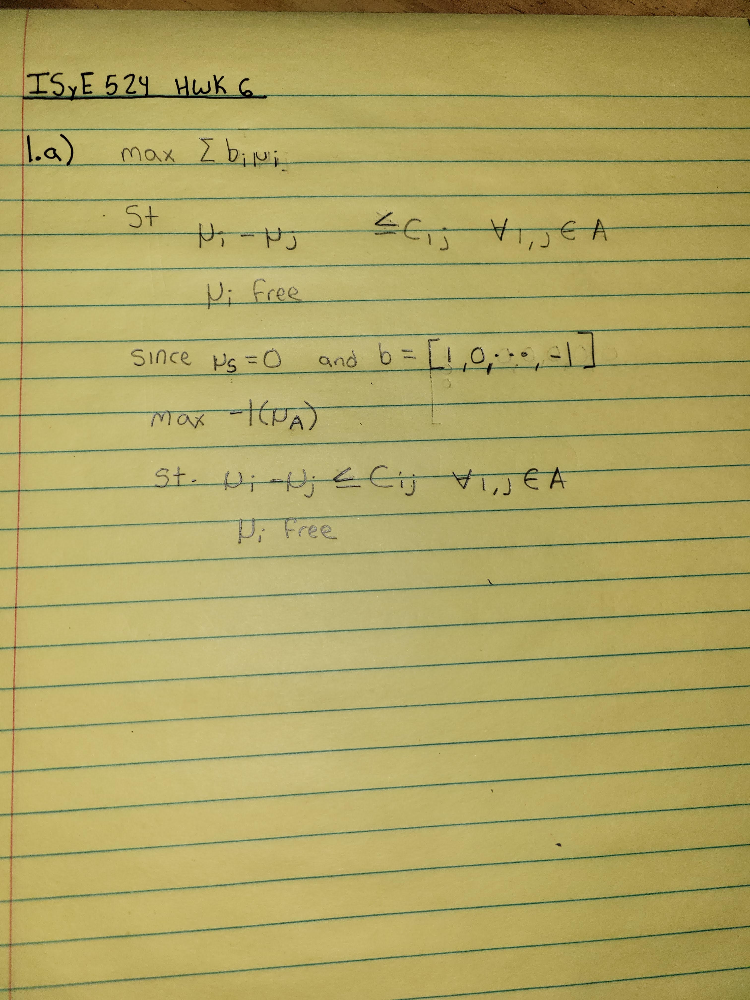{width=75%}|

Adding the normalization $\mu_S=0$ does not change its optimal value because it just just gives the problem a refrence value.  The flows will remain the same if you set it to another number the optimal value will remain the same because it just cancels out in the objective function when you expand it out. This is because $\mu_{A}$ will be greater by the value of $\mu_S$ and because the objective is $\mu_S - \mu_A$ the value irrelevent to the final optimal soloution.

### 1(b): Solve the dual

Implement the dual from 1(a) with $\mu_S=0$ and solve it. Report the
objective value and a table of node potentials. Your code should use
`mu[i]` for $\mu_i$. Different optimal potential vectors are acceptable.


In [3]:
nodes_path = [:S, :G, :O, :R, :I, :W, :A]
arcs_path = [(:S,:G), (:S,:O), (:S,:R), (:G,:O), (:G,:I),
             (:O,:R), (:O,:I), (:O,:W), (:R,:W), (:I,:W),
             (:I,:A), (:W,:A)]
c_path = Dict(zip(arcs_path, [4.0,6.0,5.0,1.0,7.0,2.0,
                              5.5,4.0,5.0,1.0,6.0,8.0]))
b_path = Dict(i => (i == :S ? 1.0 : i == :A ? -1.0 : 0.0)
              for i in nodes_path);


In [4]:
# Build and solve the dual using free variables mu[nodes_path].
# Normalize mu[:S] to zero; report the objective and node potentials.

MCNF = Model(HiGHS.Optimizer)

@variable(MCNF, mu[i in nodes_path])

@objective(MCNF, Max, -mu[:A])

@constraint(MCNF, flowbalance[(i,j) in arcs_path],
    mu[i]-mu[j] <= c_path[i,j])

@constraint(MCNF, mu[:S] == 0)

optimize!(MCNF)
status = termination_status(MCNF)
println("Termination status: ", status)
status == MOI.OPTIMAL || error("HiGHS stopped with status $(status).")
is_solved_and_feasible(MCNF) || error("No feasible optimal solution is available.")

shortest_time = objective_value(MCNF)

println("Shortest time is: ", shortest_time, " Minuites")

node_potentials = DataFrame(
    flows = -(value.(mu[(i)] for i in nodes_path)),
    node= collect(nodes_path),
)

display(node_potentials)

Running HiGHS 1.15.1 (git hash: 04024d701f): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Using BLAS: blastrampoline 
LP has 13 rows; 7 cols; 25 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+00]
  Cost    [1e+00, 1e+00]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 8e+00]
Presolving model
0 rows, 0 cols, 0 nonzeros 0s
0 rows, 0 cols, 0 nonzeros 0s
Presolve reductions: rows 0(-13); columns 0(-7); nonzeros 0(-25) - Reduced to empty
Performed postsolve
Solving the original LP from the solution after postsolve

Model status        : Optimal
Objective value     :  1.6500000000e+01
P-D objective error :  0.0000000000e+00
HiGHS run time      :          0.00
Termination status: OPTIMAL
Shortest time is: 16.5 Minuites


Row,flows,node
,Float64,Symbol
1,0.0,S
2,4.0,G
3,5.0,O
4,5.0,R
5,10.5,I
6,9.0,W
7,16.5,A


**Your reported results:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

The shortest time for this network is 16.5 minuites. 

|Node Potential |Value (minuites)|
|:---|---:|
|S|0|
|G|4|
|O|5|
|R|5|
|I|10.5|
|W|9|
|A|16.5|

### 1(c): Interpret the potentials and certify a route

For any feasible potential vector normalized by $\mu_S=0$, add the arc
inequalities along an arbitrary directed path from S to a node $i$.
Use the resulting inequality to interpret $-\mu_i$. Must it equal the
shortest S–$i$ distance at **every** node in an optimal dual solution?
Explain briefly.

Use the route **S–G–O–I–A** to give an optimality certificate: compute its
travel time, check that its arcs are tight in your optimal dual solution,
and explain why the route and potential vector together prove optimality.
State the complementary-slackness condition being used.


**Your answer and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

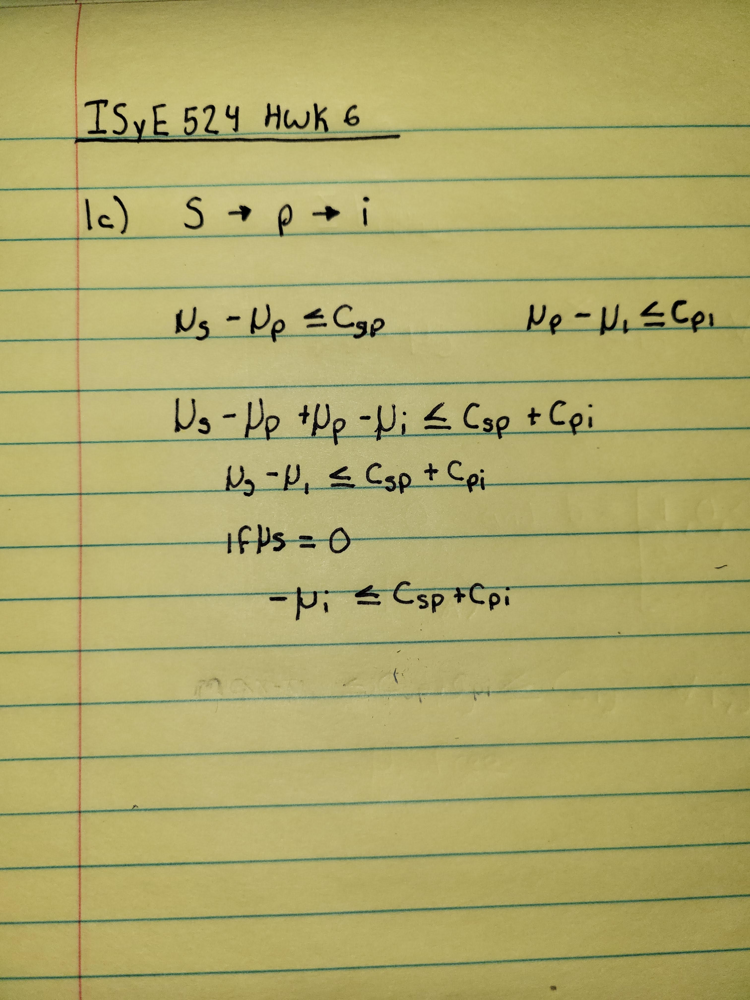{width=75%}

$- \mu_{i}$ must equal the shortest S–$i$ distance at every node in an optimal dual solution becasue it is bounded by the sums of the arc distances on the path and complimentary slackness means that the equality will become tight on the optimal path and $- \mu_{i} = C_{sp} + C_{pi}$ 

In [12]:
S_G=-(node_potentials.flows[1]-node_potentials.flows[2])
G_O=-(node_potentials.flows[2]-node_potentials.flows[3])
O_I=-(node_potentials.flows[3]-node_potentials.flows[5])
I_A=-(node_potentials.flows[5]-node_potentials.flows[7])

println("S to G: ",S_G," G to O: ",G_O," O to I: ",O_I," I to A: ",I_A)

if S_G - c_path[:S,:G] ==0
    println("S to G constraint is tight")
end
if G_O - c_path[:G,:O] ==0
    println("G to O constraint is tight")
end
if O_I - c_path[:O,:I] ==0
    println("O to I constraint is tight")
end
if I_A - c_path[:I,:A] ==0
    println("I to A constraint is tight")
end


S to G: 4.0 G to O: 1.0 O to I: 5.5 I to A: 6.0
S to G constraint is tight
G to O constraint is tight
O to I constraint is tight
I to A constraint is tight


Becasue every constraint in S-G-O-I-A is tight it means that the all other primal variables are 0 because we only send 1 through the network and every node with a tight constraint will have values $ >0$. This is because the 1 flow sent must flow through the tight constraints and 0 must flow through the non tight constraints. The complimentary slackness rule used in this case is that if the constraint isnt tight it must have 0 flow. 

## 2: Maximum flow — a minimum-cut certificate

Revisit the six-node network from HW05. Each arc label is its capacity in
units of flow per hour. Intermediate nodes neither create nor consume flow.

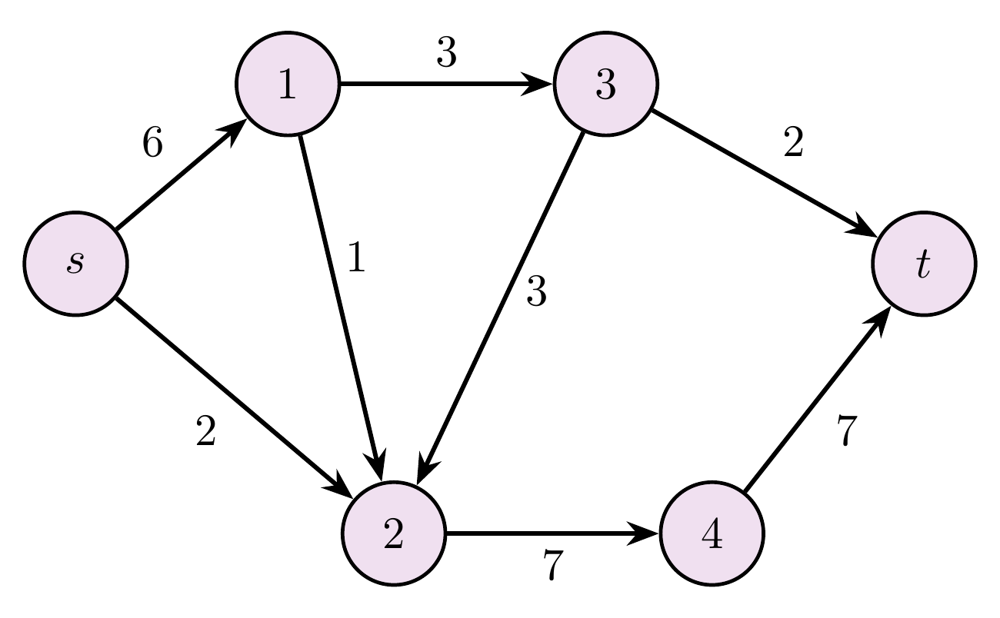{width=70%}

Let $\mathcal N=\{s,1,2,3,4,t\}$ and let $\mathcal E$ contain only the
eight physical arcs shown in the figure. Continuous variables
$x_{ij}\ge0$ denote arc flows, and $v\ge0$ denotes the flow on an
additional feedback arc $(t,s)$. For deriving the dual, write maximum
flow in the following equivalent **maximization** form:

$$
\begin{aligned}
\max_{x,v}\quad &v\\
\text{s.t.}\quad
&\sum_{j:(i,j)\in\mathcal E}x_{ij}
 -\sum_{j:(j,i)\in\mathcal E}x_{ji}
 +\alpha_i v=0 &&i\in\mathcal N,\\
&x_{ij}\le u_{ij} &&(i,j)\in\mathcal E,\\
&x_{ij}\ge0 &&(i,j)\in\mathcal E,\qquad v\ge0,
\end{aligned}
$$

where $\alpha_s=-1$, $\alpha_t=1$, and $\alpha_i=0$ at intermediate
nodes. The feedback arc has no finite capacity. This maximizes the same
throughput as HW05's minimization of $-v$.

### 2(a): Derive the dual

Use **free node potentials $\pi_i$** for the balance equalities and
**nonnegative multipliers $\lambda_{ij}$** for the physical-arc capacity
constraints. Write the dual LP in indexed form. Include the constraint
arising from $v\ge0$ and all variable domains. You may normalize
$\pi_s=0$.


**Your answer and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]

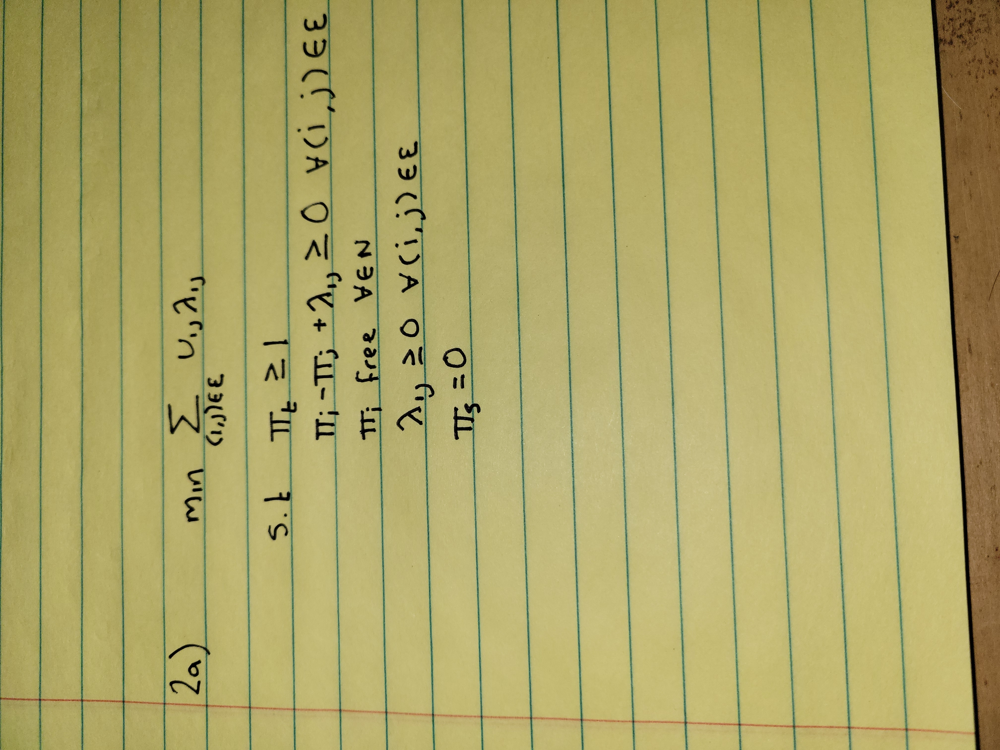{width=75%}

### 2(b): Construct a complementary dual solution

The following physical-arc flow is supplied:

| Arc | Capacity $u_{ij}$ | Flow $x_{ij}$ |
| :--- | ---: | ---: |
| s → 1 | 6 | 4 |
| s → 2 | 2 | 2 |
| 1 → 2 | 1 | 1 |
| 1 → 3 | 3 | 3 |
| 3 → 2 | 3 | 1 |
| 2 → 4 | 7 | 4 |
| 3 → t | 2 | 2 |
| 4 → t | 7 | 4 |

Check its capacities and node balances, and determine the feedback flow $v$.
Starting with $\pi_s=0$, **use complementary slackness by hand** to
construct a dual solution complementary to this flow. Show which multipliers
must be zero and which dual constraints must be tight. Check dual feasibility
and compute the dual objective.

Then implement and solve your dual LP in Julia/JuMP to check the optimal value.
Use `pi[i]` and `lambda[a]` for $\pi_i$ and $\lambda_{ij}$.
Report the value and one optimal dual vector; solver output does not replace
your complementary-slackness argument.


**Your answer and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]


| Arc | Capacity $u_{ij}$ | Flow $x_{ij}$ | Slack/Tight |
| :--- | ---: | ---: | ---: |
| s → 1 | 6 | 4 | Slack |
| s → 2 | 2 | 2 | Tight |
| 1 → 2 | 1 | 1 | Tight |
| 1 → 3 | 3 | 3 | Tight |
| 3 → 2 | 3 | 1 | Slack |
| 2 → 4 | 7 | 4 | Slack |
| 3 → t | 2 | 2 | Slack |
| 4 → t | 7 | 4 | Slack |


| Node | Inflow | Outflow | 
| :--- | ---: | ---: | 
| 1 | 4 | 4 | 
| 2 | 4 | 4 | 
| 3 | 3 | 3 | 
| 4 | 4 | 4 | 

$v= x_{s1} + x_{s2}$

$v= 4+2 = 6 $


In [18]:
# Strings "1", ..., "4" label the intermediate nodes in the figure.
nodes_flow = ["s", "1", "2", "3", "4", "t"]
arcs_flow = [("s","1"), ("s","2"), ("1","2"), ("1","3"),
             ("3","2"), ("2","4"), ("3","t"), ("4","t")]
u_flow = Dict(zip(arcs_flow, [6.0,2.0,1.0,3.0,3.0,7.0,2.0,7.0]))
x_given = Dict(zip(arcs_flow, [4.0,2.0,1.0,3.0,1.0,4.0,2.0,4.0]));


In [30]:
# Build and solve the dual with free pi and nonnegative lambda.
# Normalize pi["s"] to zero; report the objective and optimal vectors.


MCNF2 = Model(HiGHS.Optimizer)

@variable(MCNF2, lamda[(i,j) in arcs_flow] >= 0)

@variable(MCNF2, pi[i in nodes_flow])

@objective(MCNF2, Min, sum(u_flow[(i,j)]*lamda[(i,j)] for (i,j) in arcs_flow))

@constraint(MCNF2, flowbalance[(i,j) in arcs_flow],
    pi[i]-pi[j]+lamda[(i,j)]>=0)

@constraint(MCNF2, pi[:"t"] >= 1)

@constraint(MCNF2, pi[:"s"] == 0)


optimize!(MCNF2)
status = termination_status(MCNF2)
println("Termination status: ", status)
status == MOI.OPTIMAL || error("HiGHS stopped with status $(status).")
is_solved_and_feasible(MCNF2) || error("No feasible optimal solution is available.")

maximum_flow = objective_value(MCNF2)

println("Maximum Flow is: ", maximum_flow, " Products per Hr")

node_potentials = DataFrame(
    flows = (value.(lamda[(i,j)] for (i,j) in arcs_flow)),
    arcs= collect(arcs_flow),
)

display(node_potentials)

Running HiGHS 1.15.1 (git hash: 04024d701f): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Using BLAS: blastrampoline 
LP has 10 rows; 14 cols; 26 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+00]
  Cost    [1e+00, 7e+00]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 1e+00]
Presolving model
8 rows, 12 cols, 20 nonzeros 0s
4 rows, 8 cols, 15 nonzeros 0s
2 rows, 3 cols, 4 nonzeros 0s
Presolve reductions: rows 2(-8); columns 3(-11); nonzeros 4(-22) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     3.0000000000e+00 Pr: 2(2) 0.0s
          1     6.0000000000e+00 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model status        : Optimal
Simplex   iterations: 1
Objective value     :  6.0000000000e+00
P-D objective error :  0.0000000000e+00
HiGHS run time      :          0.00
Termination 

Row,flows,arcs
,Float64,Tuple…
1,0.0,"(""s"", ""1"")"
2,1.0,"(""s"", ""2"")"
3,1.0,"(""1"", ""2"")"
4,1.0,"(""1"", ""3"")"
5,0.0,"(""3"", ""2"")"
6,0.0,"(""2"", ""4"")"
7,0.0,"(""3"", ""t"")"
8,0.0,"(""4"", ""t"")"


### 2(c): Identify the cut and explain the certificate

Use your constructed potentials from 2(b) to specify a cut $(S,\overline S)$,
where $s\in S$ and $t\in\overline S$. List the **physical arcs directed
from $S$ to $\overline S$** and sum their capacities.

Explain why the capacity of any such cut is an upper bound on every feasible
s–t flow. Use your cut and the supplied feasible flow to conclude that
the flow is maximum and the cut is minimum. Relate the cut arcs to your
capacity multipliers $\lambda_{ij}$.


**Your answer and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]


## 3: Campus Awards — production in whole batches

A small workshop makes football trophies and soccer trophies. Production
must occur in complete batches, using the resources below.

| Product | Trophies per batch | Labor per batch (hours) | Material per batch (kg) | Profit per batch ($) |
| :--- | ---: | ---: | ---: | ---: |
| Football trophies | 10 | 3 | 2 | 40 |
| Soccer trophies | 20 | 2 | 4 | 50 |

For the coming week, **19 labor hours** and **23 kg of material** are
available. All completed trophies can be sold. Profit in the table is net
of variable production costs; there are no setup costs. No fractional
batches are permitted, and no minimum production is required.

Use these scalar decision variables:

- $x_1\in\mathbb Z_{\ge0}$: the number of complete football-trophy batches.
- $x_2\in\mathbb Z_{\ge0}$: the number of complete soccer-trophy batches.

### 3(a): Formulate and solve the integer program

Write the profit-maximizing IP, including both resource constraints and
variable domains. Implement it with scalar JuMP variables `x1` and `x2`.
Report the optimal batch counts, numbers of trophies, total profit, and
labor and material used.


**Your formulation and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]


In [ ]:
# Formulate and solve the IP with scalar integer variables x1 and x2.
# Report batches, trophies, profit, and resource use.


### 3(b): Solve the LP relaxation

Replace the integer domains by $x_1,x_2\ge0$ continuous and solve the
resulting LP. Report its batch counts and profit. Explain why this LP
value is an **upper bound** on the IP optimum and why its production
plan need not be implementable. Compute the difference between the LP
and IP objective values in dollars.


In [ ]:
# Solve the same model with continuous scalar variables x1 and x2.
# Report the relaxed plan, objective, and dollar difference from the IP.


**Your results and explanation:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]


### 3(c): Does rounding repair the relaxed solution?

Starting from the relaxed batch counts in 3(b), consider two plans:

1. Round **each** batch count to its nearest integer.
2. Round **each** batch count down to the next lower integer.

For each plan, report the batch counts and resource requirements, and check
feasibility. For each feasible plan, report its profit and compare it with
the IP optimum. What does this example show about using rounding as a
replacement for solving the IP? You may calculate these quantities by hand
or use the optional code cell below.


In [ ]:
# Optional: compare nearest-integer and rounded-down plans.


**Your answer and reasoning:**

[Type your answer here, or insert a clear photograph/scan of handwritten work.]


## Collaboration and LLM-use statement — required

Complete this statement as the **very last part of your homework**. Be specific enough that a reader can understand what work you did yourself and how others or LLMs helped you learn.

- **People:** Give the name of every person you collaborated with, identify the problem/subpart you discussed, and explain the nature of the collaboration. If you worked alone, explicitly state that you did not collaborate with anyone.
- **LLMs/tools:** Name every LLM or AI assistant you used and identify the model/version as precisely as available. If the interface did not show a model/version, say so. If you used none, explicitly state that you did not use an LLM or AI assistant.
- **Specific assistance and learning:** For each tool, identify the problem/subpart, describe what you asked it to help with, what suggestions you used or rejected, and how the interaction helped you understand the mathematics or implementation. Explain how you checked the suggestions. “I used ChatGPT for help” is not sufficiently specific.

Disclosure does not replace the requirement that your submitted formulation, implementation, and explanation be your own work and that you understand them.


**People and collaboration:**

[Names, problem/subparts, and what you discussed; or explicitly state that you worked alone.]

**LLMs/tools and models:**

[Tool names and models/versions, or explicitly state that you used none.]

**How I used the assistance, what I learned, and how I checked it:**

[Specific details for each tool and relevant problem/subpart; state not applicable if you used none.]
